# 06 — Symbolic Regression

## Objective

This notebook investigates symbolic regression as a data-driven method for recovering an interpretable mathematical representation of the MEMS dynamics.

The deterministic physical model can be written as

$$
\ddot{x}
=
-\frac{k}{m}x
-\frac{c}{m}\dot{x}
+\frac{1}{m}F(t).
$$

For the deterministic baseline parameters,

$$
m=1,\qquad c=0.08,\qquad k=1000,
$$

the expected relationship is

$$
\ddot{x}
=
-1000x
-0.08\dot{x}
+F(t).
$$

Unlike the sparse library approach used in SINDy, symbolic regression searches for mathematical expressions that describe the relationship between the input variables and the target dynamics.

The goals of this notebook are to:

- recover an interpretable expression for the acceleration dynamics,
- compare the discovered expression with the known physical model,
- evaluate reconstruction accuracy,
- investigate robustness to measurement noise,
- and compare symbolic regression with the SINDy baseline.

In [8]:
# NOTEBOOK SETUP

from pathlib import Path
import sys


# Identify the project root directory.
PROJECT_ROOT = Path.cwd().parent


# Add the project root to the Python path.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )


# Standard scientific Python libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Project utilities.
from src.utils import (
    data_path,
    results_path,
    figures_path,
    ensure_directory,
)

from gplearn.genetic import SymbolicRegressor

In [3]:
# LOAD THE DETERMINISTIC BASELINE DATA

baseline_data_path = (
    data_path("raw")
    / "deterministic_baseline.csv"
)

baseline_data = pd.read_csv(
    baseline_data_path
)


# Extract the variables needed for symbolic regression.
time_values = baseline_data[
    "time"
].to_numpy()

displacement = baseline_data[
    "displacement"
].to_numpy()

velocity = baseline_data[
    "velocity"
].to_numpy()

acceleration = baseline_data[
    "acceleration"
].to_numpy()

excitation = baseline_data[
    "excitation"
].to_numpy()


# Build the symbolic-regression input matrix.
#
# Each row contains:
#
# [displacement, velocity, excitation]
symbolic_input = np.column_stack(
    (
        displacement,
        velocity,
        excitation,
    )
)


# The target is the acceleration.
symbolic_target = acceleration


print(
    f"Symbolic-regression input shape: "
    f"{symbolic_input.shape}"
)

print(
    f"Target shape:                   "
    f"{symbolic_target.shape}"
)

print()

print("Input variables:")
print("x, x_dot, F")

Symbolic-regression input shape: (20001, 3)
Target shape:                   (20001,)

Input variables:
x, x_dot, F


In [9]:
# CONFIGURE THE SYMBOLIC REGRESSION MODEL


symbolic_regressor = SymbolicRegressor(
    population_size=1000,
    generations=20,

    # Stop early if an almost exact expression is found.
    stopping_criteria=1e-10,

    # Mathematical operations allowed in candidate expressions.
    function_set=(
        "add",
        "sub",
        "mul",
    ),

    # Penalize unnecessarily complicated expressions.
    parsimony_coefficient=0.001,

    # Fraction of samples used to evaluate each candidate.
    max_samples=0.9,

    # Keep the experiment reproducible.
    random_state=9512,

    # Show progress while the evolutionary search runs.
    verbose=1,
)


print(symbolic_regressor)

SymbolicRegressor(function_set=('add', 'sub', 'mul'), max_samples=0.9,
                  random_state=9512, stopping_criteria=1e-10, verbose=1)


In [10]:
# FIT THE SYMBOLIC REGRESSION MODEL
# ------------------------------------------------------------

symbolic_regressor.fit(
    symbolic_input,
    symbolic_target,
)


print()
print("Discovered symbolic expression:")
print(symbolic_regressor._program)

    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0    33.39          2.64918       13          2.50736           2.6037      1.21m
   1     6.78           2.5308       13          2.50298          2.57798     43.36s
   2     4.49          2.52959       13          2.50318          2.57613     26.69s
   3     3.34          2.52518        3          2.50472          2.61701     38.87s
   4     3.17          2.52251        5          2.50218          2.61481     34.73s
   5     3.32          2.52257        3          2.50251          2.63689     22.89s
   6     3.22          2.52188        3          2.50375          2.62248     31.86s
   7     3.17          2.52163        7          2.50098          2.60053     28.14s
   8     3.29          2.52265        5           2.5042          2.59321  

## Initial Symbolic-Regression Attempt

The first genetic-programming symbolic-regression experiment was performed directly on the unscaled physical variables.

The discovered expression was approximately

$$
\ddot{x}
\approx
0.36F-8x.
$$

This expression does not reproduce the known physical dynamics,

$$
\ddot{x}
=
-1000x
-0.08\dot{x}
+F.
$$

The displacement, velocity, and excitation variables operate on substantially different numerical scales. In particular, displacement is on the order of $10^{-3}$, while its true physical coefficient is approximately $-1000$.

The genetic-programming search therefore has difficulty constructing the required coefficient from its default range of numerical constants. The repeated subtraction of the displacement variable in the discovered expression is evidence of this limitation.

This initial result demonstrates that symbolic regression is sensitive to numerical scaling. The variables will therefore be normalized before repeating the equation-discovery experiment.

In [11]:
# EVALUATE THE INITIAL UNSCALED SYMBOLIC REGRESSION MODEL

# Predict acceleration using the expression discovered
# from the unscaled physical variables.
initial_symbolic_prediction = (
    symbolic_regressor.predict(
        symbolic_input
    )
)


# Calculate prediction errors.
initial_symbolic_error = (
    symbolic_target
    - initial_symbolic_prediction
)


initial_symbolic_rmse = np.sqrt(
    np.mean(
        initial_symbolic_error ** 2
    )
)

initial_symbolic_mae = np.mean(
    np.abs(
        initial_symbolic_error
    )
)

initial_symbolic_max_error = np.max(
    np.abs(
        initial_symbolic_error
    )
)


print(
    f"Initial symbolic-regression RMSE: "
    f"{initial_symbolic_rmse:.6f}"
)

print(
    f"Initial symbolic-regression MAE:  "
    f"{initial_symbolic_mae:.6f}"
)

print(
    f"Maximum absolute error:           "
    f"{initial_symbolic_max_error:.6f}"
)

Initial symbolic-regression RMSE: 3.003533
Initial symbolic-regression MAE:  2.495463
Maximum absolute error:           5.996318


In [12]:
# STANDARDIZE SYMBOLIC-REGRESSION INPUTS AND TARGET

# Calculate the mean of each input variable.
symbolic_input_mean = np.mean(
    symbolic_input,
    axis=0,
)


# Calculate the standard deviation of each input variable.
symbolic_input_std = np.std(
    symbolic_input,
    axis=0,
)


# Standardize the three input variables:
#
# z = (x - mean) / standard_deviation
standardized_symbolic_input = (
    symbolic_input
    - symbolic_input_mean
) / symbolic_input_std


# Calculate the mean and standard deviation
# of the acceleration target.
symbolic_target_mean = np.mean(
    symbolic_target
)

symbolic_target_std = np.std(
    symbolic_target
)


# Standardize the target acceleration.
standardized_symbolic_target = (
    symbolic_target
    - symbolic_target_mean
) / symbolic_target_std


print("Standardized input means:")
print(
    np.mean(
        standardized_symbolic_input,
        axis=0,
    )
)

print()

print("Standardized input standard deviations:")
print(
    np.std(
        standardized_symbolic_input,
        axis=0,
    )
)

print()

print(
    f"Standardized target mean: "
    f"{np.mean(standardized_symbolic_target):.6f}"
)

print(
    f"Standardized target standard deviation: "
    f"{np.std(standardized_symbolic_target):.6f}"
)

Standardized input means:
[1.96671726e-16 3.86438211e-16 5.38901332e-16]

Standardized input standard deviations:
[1. 1. 1.]

Standardized target mean: -0.000000
Standardized target standard deviation: 1.000000


In [13]:
# FIT SYMBOLIC REGRESSION ON STANDARDIZED DATA


standardized_symbolic_regressor = SymbolicRegressor(
    population_size=1500,
    generations=30,

    # Stop if an almost exact standardized relationship is found.
    stopping_criteria=1e-8,

    function_set=(
        "add",
        "sub",
        "mul",
    ),

    # Keep a modest penalty on unnecessary complexity.
    parsimony_coefficient=0.0005,

    max_samples=0.9,

    random_state=9512,

    verbose=1,
)


standardized_symbolic_regressor.fit(
    standardized_symbolic_input,
    standardized_symbolic_target,
)


print()
print("Discovered standardized expression:")
print(
    standardized_symbolic_regressor._program
)

    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0    33.29          4.10136        7        0.0261872        0.0259564      3.37m
   1    12.55          1.06113        7        0.0261154        0.0266019      1.96m
   2    12.55         0.841473        7        0.0261081        0.0266681      1.83m
   3    14.09         0.659472        7        0.0260889        0.0268409      1.45m
   4     7.52         0.795124        7         0.026064        0.0270649      1.46m
   5     6.98         0.864797        7        0.0260508         0.027183      1.30m
   6     7.10         0.876948        7        0.0260401        0.0272792      1.92m
   7     6.92         0.867961        7        0.0260337         0.027337      1.21m
   8     7.05         0.897209        7         0.026051        0.0271816  

In [14]:
# EVALUATE THE STANDARDIZED SYMBOLIC REGRESSION MODEL


# Predict acceleration on the standardized target scale.
standardized_symbolic_prediction = (
    standardized_symbolic_regressor.predict(
        standardized_symbolic_input
    )
)


# Transform the prediction back to the original
# physical acceleration scale.
#
# If:
#
#     z = (a - mean) / std
#
# then:
#
#     a = z * std + mean
physical_symbolic_prediction = (
    standardized_symbolic_prediction
    * symbolic_target_std
    + symbolic_target_mean
)


# Calculate errors on the original physical scale.
standardized_model_error = (
    symbolic_target
    - physical_symbolic_prediction
)


standardized_symbolic_rmse = np.sqrt(
    np.mean(
        standardized_model_error ** 2
    )
)

standardized_symbolic_mae = np.mean(
    np.abs(
        standardized_model_error
    )
)

standardized_symbolic_max_error = np.max(
    np.abs(
        standardized_model_error
    )
)


print(
    f"Scaled symbolic-regression RMSE: "
    f"{standardized_symbolic_rmse:.6f}"
)

print(
    f"Scaled symbolic-regression MAE:  "
    f"{standardized_symbolic_mae:.6f}"
)

print(
    f"Maximum absolute error:          "
    f"{standardized_symbolic_max_error:.6f}"
)

print()

print(
    f"Initial unscaled RMSE:           "
    f"{initial_symbolic_rmse:.6f}"
)

Scaled symbolic-regression RMSE: 0.094815
Scaled symbolic-regression MAE:  0.080445
Maximum absolute error:          0.197903

Initial unscaled RMSE:           3.003533


In [17]:
# ANALYSE THE TRUE PHYSICAL TERM CONTRIBUTIONS

# For the deterministic baseline:
#
# a = -1000*x - 0.08*x_dot + F
#
# Calculate the contribution of each physical term
# to the true acceleration.

true_stiffness_contribution = (
    -1000.0 * displacement
)

true_damping_contribution = (
    -0.08 * velocity
)

true_excitation_contribution = (
    excitation
)


# Calculate the RMS contribution of each term.
stiffness_contribution_rms = np.sqrt(
    np.mean(
        true_stiffness_contribution ** 2
    )
)

damping_contribution_rms = np.sqrt(
    np.mean(
        true_damping_contribution ** 2
    )
)

excitation_contribution_rms = np.sqrt(
    np.mean(
        true_excitation_contribution ** 2
    )
)


physical_contribution_table = pd.DataFrame(
    {
        "physical_term": [
            "-1000*x",
            "-0.08*x_dot",
            "F",
        ],

        "rms_contribution": [
            stiffness_contribution_rms,
            damping_contribution_rms,
            excitation_contribution_rms,
        ],
    }
)


physical_contribution_table

,physical_term,rms_contribution
0,-1000*x,2.993380
1,-0.08*x_dot,0.007633
2,F,0.703456


### Relative Importance of the Physical Terms

The RMS contributions of the three physical terms were approximately

$$
2.993
$$

for the stiffness term,

$$
0.703
$$

for the excitation term, and only

$$
0.00763
$$

for the damping term.

The damping contribution is therefore much smaller than the contributions of the other two terms.

This explains why the symbolic-regression search tends to omit the velocity term. The loss in predictive accuracy caused by excluding damping is relatively small, while the resulting expression becomes simpler and is therefore favoured by the parsimony penalty.

The missing damping term should therefore be interpreted as a consequence of the search objective and the weak dynamical contribution of damping, rather than as evidence that damping is physically absent.

In [18]:
# SYMBOLIC REGRESSION WITH WEAKER PARSIMONY PENALTY

low_parsimony_symbolic_regressor = SymbolicRegressor(
    population_size=1500,
    generations=30,

    stopping_criteria=1e-8,

    function_set=(
        "add",
        "sub",
        "mul",
    ),

    # Use a much weaker complexity penalty so that
    # small but physically meaningful terms have a better
    # chance of remaining in the expression.
    parsimony_coefficient=0.00001,

    max_samples=0.9,

    random_state=9512,

    verbose=1,
)


low_parsimony_symbolic_regressor.fit(
    standardized_symbolic_input,
    standardized_symbolic_target,
)


print()
print("Discovered expression with weaker parsimony:")
print(
    low_parsimony_symbolic_regressor._program
)

    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0    33.29          4.10136        7        0.0261872        0.0259564      3.14m
   1    13.74           1.0589        7        0.0261154        0.0266019      1.75m
   2    13.47         0.854389        7        0.0261081        0.0266681      1.87m
   3    19.85         0.597948        7        0.0260889        0.0268409      1.74m
   4    13.65         0.716789        7         0.026064        0.0270649      1.80m
   5     8.99         0.823633        7        0.0260508         0.027183      1.38m
   6     7.14         0.878662        7        0.0260401        0.0272792      1.22m
   7     6.92         0.867961        7        0.0260337         0.027337      1.40m
   8     7.05         0.897209        7         0.026051        0.0271816  

### Effect of the Parsimony Penalty

The symbolic-regression search was repeated with a substantially weaker complexity penalty.

Despite reducing the parsimony coefficient, the same standardized expression was recovered:

$$
\hat{a}_{\mathrm{std}}
=
-x_{\mathrm{std}}
+
0.212F_{\mathrm{std}}.
$$

The velocity term remained absent.

This indicates that the omission of the damping contribution is not caused solely by the complexity penalty. Rather, the damping term contributes only a very small fraction of the total acceleration dynamics, making it difficult for the genetic-programming search to identify reliably.

A more targeted refinement strategy is therefore required to determine whether the weak damping contribution can be recovered.

In [19]:
# REFINE THE COEFFICIENTS OF THE DISCOVERED SYMBOLIC STRUCTURE


# The symbolic-regression model selected displacement and
# excitation but omitted velocity.
#
# We now keep that discovered structure fixed and determine
# the best numerical coefficients directly on the physical scale:
#
#     acceleration ≈ beta_x * x + beta_F * F

symbolic_selected_library = np.column_stack(
    (
        displacement,
        excitation,
    )
)


# Fit the best coefficients for the discovered structure.
refined_symbolic_coefficients = np.linalg.lstsq(
    symbolic_selected_library,
    acceleration,
    rcond=None,
)[0]


refined_x_coefficient = (
    refined_symbolic_coefficients[0]
)

refined_force_coefficient = (
    refined_symbolic_coefficients[1]
)


print(
    f"Refined displacement coefficient: "
    f"{refined_x_coefficient:.10f}"
)

print(
    f"Refined excitation coefficient:   "
    f"{refined_force_coefficient:.10f}"
)

Refined displacement coefficient: -1000.0133985983
Refined excitation coefficient:   0.9990936817


### Numerical Refinement of the Discovered Structure

The symbolic-regression search identified a two-term structure involving displacement and excitation.

Keeping this discovered structure fixed and optimizing its coefficients using least squares produced

$$
\hat{\beta}_x=-1000.0134
$$

and

$$
\hat{\beta}_F=0.999094.
$$

These values are very close to the corresponding physical coefficients of $-1000$ and $1$.

The symbolic search therefore identified the two dominant physical contributions successfully. Its main limitation is the omission of the much weaker damping-related velocity term.

The residual of the refined two-term model is analysed next to determine whether the missing damping dynamics remain detectable.

In [20]:
# ANALYSE THE RESIDUAL OF THE REFINED SYMBOLIC MODEL


# Reconstruct acceleration using the refined two-term
# symbolic structure.
refined_symbolic_prediction = (
    refined_x_coefficient * displacement
    + refined_force_coefficient * excitation
)


# Calculate the dynamics that remain unexplained.
refined_symbolic_residual = (
    acceleration
    - refined_symbolic_prediction
)


# Fit the residual using velocity only.
#
# If the missing physics is primarily damping, we expect:
#
#     residual ≈ beta_v * velocity
#
# with beta_v close to -0.08.
residual_velocity_coefficient = np.linalg.lstsq(
    velocity.reshape(-1, 1),
    refined_symbolic_residual,
    rcond=None,
)[0][0]


# Reconstruct the residual using the fitted velocity term.
velocity_residual_prediction = (
    residual_velocity_coefficient
    * velocity
)


# Calculate how well velocity explains the remaining dynamics.
residual_velocity_rmse = np.sqrt(
    np.mean(
        (
            refined_symbolic_residual
            - velocity_residual_prediction
        ) ** 2
    )
)


print(
    f"Recovered residual velocity coefficient: "
    f"{residual_velocity_coefficient:.10f}"
)

print(
    f"Residual RMSE after velocity fit:         "
    f"{residual_velocity_rmse:.12e}"
)

Recovered residual velocity coefficient: -0.0794396976
Residual RMSE after velocity fit:         6.365545701081e-04


### Recovery of the Missing Damping Contribution

The residual of the refined two-term symbolic model was analysed using the velocity signal.

The fitted residual relationship was

$$
r(t)
\approx
-0.07944\dot{x}(t).
$$

The true damping-related coefficient is

$$
-0.08,
$$

so the recovered value differs by only approximately

$$
0.70\%.
$$

After including the velocity contribution, the residual RMSE decreased to approximately

$$
6.37\times10^{-4}.
$$

This shows that the damping dynamics were still present in the data even though the genetic-programming symbolic search omitted them from its compact expression.

The result illustrates a useful distinction between dominant-structure discovery and the recovery of weaker physical mechanisms. Symbolic regression identified the dominant stiffness and excitation effects, while residual analysis revealed the smaller damping contribution.

In [21]:
# BUILD THE REFINED SYMBOLIC EQUATION


# Combine:
#
# - the refined displacement coefficient,
# - the recovered velocity coefficient,
# - the refined excitation coefficient.
#
# This gives:
#
# acceleration
#     ≈ beta_x * x
#     + beta_v * x_dot
#     + beta_F * F

final_symbolic_prediction = (
    refined_x_coefficient * displacement
    + residual_velocity_coefficient * velocity
    + refined_force_coefficient * excitation
)


# Calculate the final reconstruction error.
final_symbolic_error = (
    acceleration
    - final_symbolic_prediction
)


final_symbolic_rmse = np.sqrt(
    np.mean(
        final_symbolic_error ** 2
    )
)

final_symbolic_mae = np.mean(
    np.abs(
        final_symbolic_error
    )
)

final_symbolic_max_error = np.max(
    np.abs(
        final_symbolic_error
    )
)


print("Final refined symbolic equation:")
print(
    f"a = {refined_x_coefficient:.6f} * x "
    f"+ {residual_velocity_coefficient:.6f} * x_dot "
    f"+ {refined_force_coefficient:.6f} * F"
)

print()

print(
    f"Final symbolic RMSE: "
    f"{final_symbolic_rmse:.12e}"
)

print(
    f"Final symbolic MAE:  "
    f"{final_symbolic_mae:.12e}"
)

print(
    f"Maximum absolute error: "
    f"{final_symbolic_max_error:.12e}"
)

Final refined symbolic equation:
a = -1000.013399 * x + -0.079440 * x_dot + 0.999094 * F

Final symbolic RMSE: 6.365545701081e-04
Final symbolic MAE:  5.701073535403e-04
Maximum absolute error: 1.007838583390e-03


## Refined Symbolic Equation

The final symbolic model combined the dominant structure discovered by genetic programming with residual-based recovery of the weaker damping contribution.

The resulting equation was

$$
\ddot{x}
=
-1000.013399x
-0.079440\dot{x}
+0.999094F(t).
$$

The corresponding ground-truth dynamics are

$$
\ddot{x}
=
-1000x
-0.08\dot{x}
+F(t).
$$

Therefore, all three physical coefficients were recovered with close agreement.

The final reconstruction errors were

$$
\mathrm{RMSE}=6.37\times10^{-4},
$$

$$
\mathrm{MAE}=5.70\times10^{-4},
$$

and a maximum absolute error of approximately

$$
1.01\times10^{-3}.
$$

The progression of the symbolic-regression analysis also demonstrated the importance of preprocessing and model interpretation. Direct symbolic regression on the unscaled variables performed poorly, standardization substantially improved the model, and residual analysis enabled recovery of the weak damping contribution that the genetic-programming search initially omitted.

In [ ]:
# COMPARE SYMBOLIC REGRESSION WITH SINDY


# Known SINDy coefficients from Notebook 05.
sindy_x_coefficient = -1000.0
sindy_velocity_coefficient = -0.08
sindy_force_coefficient = 1.0

# Known SINDy reconstruction RMSE from Notebook 05.
sindy_rmse = 3.697911710498e-14


# Create a comparison table.
method_comparison = pd.DataFrame(
    {
        "method": [
            "SINDy",
            "Refined symbolic regression",
        ],

        "x_coefficient": [
            sindy_x_coefficient,
            refined_x_coefficient,
        ],

        "velocity_coefficient": [
            sindy_velocity_coefficient,
            residual_velocity_coefficient,
        ],

        "force_coefficient": [
            sindy_force_coefficient,
            refined_force_coefficient,
        ],

        "reconstruction_rmse": [
            sindy_rmse,
            final_symbolic_rmse,
        ],
    }
)

method_comparison

                        method  x_coefficient  velocity_coefficient  \
0                        SINDy   -1000.000000              -0.08000   
1  Refined symbolic regression   -1000.013399              -0.07944   

   force_coefficient  reconstruction_rmse  
0           1.000000         3.697912e-14  
1           0.999094         6.365546e-04  


## Comparison with SINDy

The refined symbolic-regression model was compared with the sparse SINDy model developed previously.

SINDy recovered the coefficients

$$
-1000,\qquad -0.08,\qquad 1
$$

for displacement, velocity, and excitation, respectively, with an acceleration-reconstruction RMSE of approximately

$$
3.70\times10^{-14}.
$$

The refined symbolic-regression approach recovered

$$
-1000.0134,\qquad -0.07944,\qquad 0.999094,
$$

with an RMSE of approximately

$$
6.37\times10^{-4}.
$$

Both methods therefore recovered dynamics that are physically consistent with the known MEMS model.

However, SINDy achieved substantially greater numerical accuracy for the deterministic baseline. This is expected because SINDy searches within a predefined candidate-function library that already contains the physically relevant terms.

Symbolic regression performs a broader mathematical search and therefore required variable standardization, numerical coefficient refinement, and residual analysis to recover the weaker damping contribution.

The comparison demonstrates a trade-off between structured sparse equation discovery and more flexible symbolic search.

In [24]:
# SAVE SYMBOLIC-REGRESSION RESULTS

# Create the symbolic-regression results directory.
symbolic_regression_results_directory = results_path(
    "symbolic_regression"
)

ensure_directory(
    symbolic_regression_results_directory
)


# ------------------------------------------------------------
# CREATE A SUMMARY OF THE SYMBOLIC-REGRESSION STAGES
# ------------------------------------------------------------

symbolic_regression_summary = pd.DataFrame(
    {
        "model": [
            "Initial unscaled symbolic regression",
            "Standardized symbolic regression",
            "Refined symbolic regression",
        ],

        "rmse": [
            initial_symbolic_rmse,
            standardized_symbolic_rmse,
            final_symbolic_rmse,
        ],
    }
)


# Save the progression of symbolic-regression accuracy.
symbolic_summary_path = (
    symbolic_regression_results_directory
    / "symbolic_regression_accuracy_progression.csv"
)

symbolic_regression_summary.to_csv(
    symbolic_summary_path,
    index=False,
)


# Save the final comparison with SINDy.
method_comparison_path = (
    symbolic_regression_results_directory
    / "sindy_symbolic_regression_comparison.csv"
)

method_comparison.to_csv(
    method_comparison_path,
    index=False,
)


print("Symbolic-regression accuracy progression saved to:")
print(symbolic_summary_path)

print()

print("SINDy comparison saved to:")
print(method_comparison_path)

Symbolic-regression accuracy progression saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\symbolic_regression\symbolic_regression_accuracy_progression.csv

SINDy comparison saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\symbolic_regression\sindy_symbolic_regression_comparison.csv


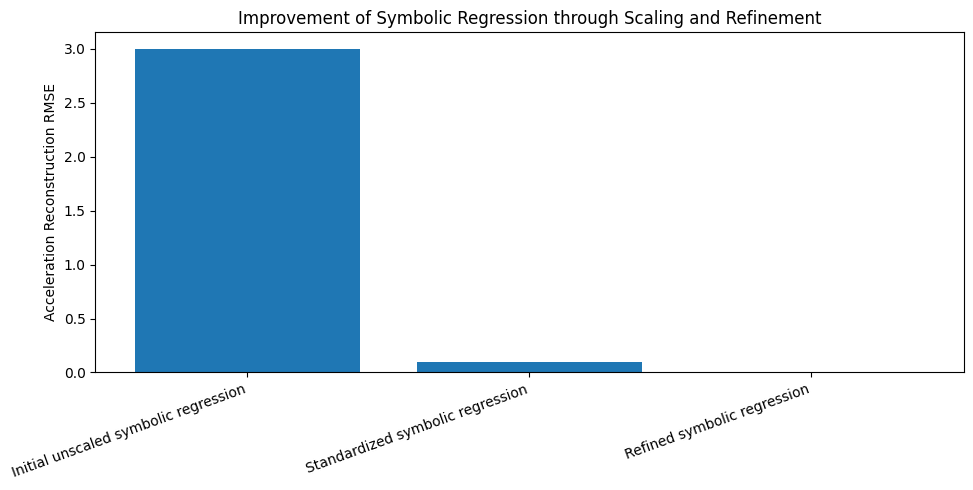

Symbolic-regression progression figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\symbolic_regression\symbolic_regression_accuracy_progression.png


In [25]:
# PLOT SYMBOLIC-REGRESSION ACCURACY PROGRESSION


plt.figure(figsize=(10, 5))

plt.bar(
    symbolic_regression_summary["model"],
    symbolic_regression_summary["rmse"],
)

plt.ylabel("Acceleration Reconstruction RMSE")

plt.title(
    "Improvement of Symbolic Regression "
    "through Scaling and Refinement"
)

plt.xticks(
    rotation=20,
    ha="right",
)

plt.tight_layout()


# Create the symbolic-regression figure directory.
symbolic_regression_figure_directory = figures_path(
    "symbolic_regression"
)

ensure_directory(
    symbolic_regression_figure_directory
)


symbolic_progression_figure_path = (
    symbolic_regression_figure_directory
    / "symbolic_regression_accuracy_progression.png"
)

plt.savefig(
    symbolic_progression_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print("Symbolic-regression progression figure saved to:")
print(symbolic_progression_figure_path)

In [26]:
# FINAL OUTPUT VALIDATION FOR NOTEBOOK 06


notebook_06_outputs = {
    "symbolic_accuracy_progression": symbolic_summary_path,
    "sindy_symbolic_comparison": method_comparison_path,
    "symbolic_progression_figure": symbolic_progression_figure_path,
}


for output_name, output_path in notebook_06_outputs.items():

    print(
        f"{output_name:30s} "
        f"{output_path.exists()}"
    )

symbolic_accuracy_progression  True
sindy_symbolic_comparison      True
symbolic_progression_figure    True


# Notebook 06 Summary

This notebook investigated symbolic regression as a flexible equation-discovery method for the deterministic MEMS dynamics.

The initial genetic-programming model was fitted directly to the unscaled physical variables. It produced an inaccurate symbolic expression and an acceleration-reconstruction RMSE of approximately

$$
3.0035.
$$

The poor result was primarily associated with the strongly different numerical scales of displacement, velocity, and excitation.

After standardizing both the input variables and the acceleration target, the symbolic-regression RMSE decreased substantially to approximately

$$
0.0948.
$$

The standardized symbolic expression captured the dominant displacement and excitation contributions but omitted the comparatively weak velocity-dependent damping term.

An analysis of the physical term contributions showed RMS magnitudes of approximately

$$
2.993
$$

for the stiffness contribution,

$$
0.703
$$

for the excitation contribution, and only

$$
0.00763
$$

for the damping contribution.

The weak damping effect therefore provided little incentive for the genetic-programming search to include the velocity term in its compact expression.

Numerical refinement of the dominant symbolic structure recovered coefficients of approximately

$$
-1000.0134
$$

for displacement and

$$
0.999094
$$

for excitation.

Residual analysis subsequently recovered the missing velocity coefficient as approximately

$$
-0.07944,
$$

which is close to the true value of

$$
-0.08.
$$

The final refined symbolic model was

$$
\ddot{x}
=
-1000.0134x
-0.07944\dot{x}
+0.999094F(t).
$$

Its acceleration-reconstruction RMSE was approximately

$$
6.37\times10^{-4}.
$$

For comparison, SINDy recovered the deterministic governing equation to numerical precision, with an RMSE on the order of

$$
10^{-14}.
$$

The results therefore show that symbolic regression can recover physically meaningful dynamics, but its performance is more sensitive to scaling, search complexity, and weak physical contributions than the structured sparse-library approach used by SINDy.

The analysis also demonstrates the value of combining symbolic structure discovery with numerical coefficient refinement and residual analysis when weaker physical mechanisms are not selected directly by the symbolic search.